In [ ]:
import os
import re
import requests
import pandas as pd
import jieba
import pdfplumber
from tqdm import tqdm
from bs4 import BeautifulSoup
# 设置路径
pdf_folder = "2023年报"
output_folder = "processed_reports"
os.makedirs(output_folder, exist_ok=True)

# 加载停用词表
stopwords = set()
with open("stopword.txt", "r", encoding="utf-8") as f: 
    for line in f:
        stopwords.add(line.strip())

# 自定义添加金融领域停用词
financial_stopwords = {"公司", "年度", "报告", "股份", "有限", "责任", "企业", "证券", "上市", "董事会", "监事会"}
stopwords |= financial_stopwords
print(stopwords.head())

# 处理PDF函数
def process_pdf(pdf_path, output_path):
    full_text = ""
    
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            # 移除表格和图像（只提取文本）
            text = page.extract_text()
            if text:
                full_text += text + "\n"
    
    # 文本清洗
    cleaned_text = re.sub(r'\d+', '', full_text)  # 去除数字
    cleaned_text = re.sub(r'[^\w\s]', '', cleaned_text)  # 去除标点符号和特殊字符
    cleaned_text = re.sub(r'\s+', ' ', cleaned_text)  # 合并多个空格
    
    # 中文分词
    words = jieba.cut(cleaned_text, cut_all=False)
    # 去除停用词和单字词
    filtered_words = [word for word in words if word not in stopwords and len(word) > 1]
    
    # 保存结果
    with open(output_path, "w", encoding="utf-8") as f:
        f.write(" ".join(filtered_words))

# 批量处理所有PDF
pdf_files = [f for f in os.listdir(pdf_folder) if f.endswith(".pdf")]
print(f"找到 {len(pdf_files)} 份年报需要处理...")

for filename in tqdm(pdf_files, desc="处理年报"):
    pdf_path = os.path.join(pdf_folder, filename)
    output_path = os.path.join(output_folder, filename.replace(".pdf", "_processed.txt"))
    process_pdf(pdf_path, output_path)

print(f"\n处理完成！结果已保存至 {output_folder} 文件夹")

In [1]:
import numpy as np 
import pandas as pd 

#计算次年收益率及两年后收益率
# data = pd.read_excel('/kaggle/input/return-data/2023-2024TRD_Year.xlsx')
data = pd.read_excel('/kaggle/input/2025-data/2024-2025TRD_Year.xlsx')
# print(data)
return_next = []
return_2years = []
report_id = []
for i in range(1000):
    rn = data["Yclsprc"][i]/data["Yopnprc"][i]-1
    if data["Trdynt"][i]==2024:
        report_id.append(data['Stkcd'][i])
        return_next.append(rn)
    else:
        return_2years.append(rn)
df_returns= pd.DataFrame({
    "report_id": report_id,
    "return_next": return_next,
    "return_2years": return_2years
})

# 将report_id补齐为6位数字符串
df_returns['report_id'] = df_returns['report_id'].astype(str).str.zfill(6)
print(df_returns)


    report_id  return_next  return_2years
0      000538     0.219239      -0.066432
1      000937    -0.114846      -0.088748
2      000938     0.440476      -0.127636
3      000948     0.110890       0.264196
4      000949     0.241486      -0.034913
..        ...          ...            ...
495    600089    -0.072105      -0.062107
496    600094     0.213333      -0.148352
497    600095    -0.041278       0.396936
498    600096     0.427657      -0.014798
499    600097    -0.051450       0.039841

[500 rows x 3 columns]


In [2]:
import os
import pandas as pd

# 设置路径
input_path = "/kaggle/input/processed-reports-all/processed_reports"
output_path = "/kaggle/working/final_data.csv"

# 处理文本文件
text_data_list = []
for fname in os.listdir(input_path):
    if fname.endswith(".txt"):
        try:
            code, year = fname.split("_")[:2]
            with open(f"{input_path}/{fname}", "r", encoding="utf-8") as f:
                text = f.read().strip()
            text_data_list.append({
                "report_id": code,
                "year": int(year),
                "report_text": text
            })
        except:
            continue

# 合并数据
text_data = pd.DataFrame(text_data_list)
df_all = pd.merge(df_returns, text_data, on="report_id")
df_all.to_csv(output_path, index=False)
print("处理完成！\n示例如下：")
print(df_all.head(4))

处理完成！
示例如下：
  report_id  return_next  return_2years  year  \
0    000538     0.219239      -0.066432  2023   
1    000937    -0.114846      -0.088748  2023   
2    000938     0.440476      -0.127636  2023   
3    000948     0.110890       0.264196  2023   

                                         report_text  
0  云南白药 集团股份 有限公司 年度报告 全文 云南白药 集团股份 有限公司 年度报告 云南白...  
1  冀中 能源 有限公司 年度报告 全文 冀中 能源 年度报告 全文 冀中 能源 有限公司 年度...  
2  紫光 有限公司 二零 二三年 年度报告 公告 编号 紫光 有限公司 第一节 重要 提示 目录...  
3  云南 电子 信息产业 有限公司 年度报告 全文 云南 电子 信息产业 有限公司 年度报告 云...  


In [3]:
#安装依赖包:pip install pandas scikit-learn gensim torch transformers

import os
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import gensim
from gensim.models import Word2Vec, Doc2Vec
from gensim.models.doc2vec import TaggedDocument

import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn, optim
from transformers import BertTokenizer, BertModel

# ========== 加载数据 ==========
# 替换成实际文件路径，下附每列参考格式
df = df_all.copy()
...
#report_id,year,report_text,return_next,return_2years
#000001,2020,"公司 坚持 创新 驱动 ...",0.123,0.312
#000002,2022,"行业 景气 度 提升 ...",-0.05,-0.18
...

# ========== 训练集和测试集划分函数 ==========
def make_splits(df, target_col, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(
        df['report_text'],
        df[target_col],
        test_size=test_size,
        random_state=random_state
    )
    return X_train, X_test, y_train.values, y_test.values

# ========== 词袋模型 + 线性回归 ==========
def run_bow_lr(df, target_col):
    print(f"\n【词袋模型 + 线性回归】预测目标：{target_col}")
    X_train, X_test, y_train, y_test = make_splits(df, target_col)
    vectorizer = CountVectorizer(max_features=5000)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec  = vectorizer.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)

    mse = mean_squared_error(y_test, y_pred)
    print(f"测试集 MSE：{mse:.6f}")
    return mse

# ========== Word2Vec 向量平均 + 线性回归 ==========
def run_w2v_avg_lr(df, target_col, w2v_size=100, w2v_min_count=2):
    print(f"\n【Word2Vec + 均值向量 + 线性回归】预测目标：{target_col}")
    tokenized = [text.split() for text in df['report_text']]
    w2v = Word2Vec(sentences=tokenized, vector_size=w2v_size, min_count=w2v_min_count, workers=4, epochs=10)

    def doc_vector(doc):
        vecs = [w2v.wv[word] for word in doc if word in w2v.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(w2v_size)

    doc_vecs = np.vstack([doc_vector(doc) for doc in tokenized])
    X = pd.DataFrame(doc_vecs)
    y = df[target_col].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    print(f"测试集 MSE：{mse:.6f}")
    return mse

# ========== Doc2Vec + 线性回归 ==========
def run_d2v_lr(df, target_col, d2v_size=100, d2v_min_count=2):
    print(f"\n【Doc2Vec + 线性回归】预测目标：{target_col}")
    tagged = [TaggedDocument(words=text.split(), tags=[str(i)]) for i, text in enumerate(df['report_text'])]
    d2v = Doc2Vec(vector_size=d2v_size, min_count=d2v_min_count, workers=4, epochs=20)
    d2v.build_vocab(tagged)
    d2v.train(tagged, total_examples=d2v.corpus_count, epochs=d2v.epochs)

    doc_vecs = np.vstack([d2v.dv[str(i)] for i in range(len(df))])
    X = pd.DataFrame(doc_vecs)
    y = df[target_col].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    print(f"测试集 MSE：{mse:.6f}")
    return mse

# ========== 中文BERT + 回归微调 ==========
class ReportDataset(Dataset):
    def __init__(self, texts, targets, tokenizer, max_len=512):
        self.texts = texts
        self.targets = targets
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids': enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'target': torch.tensor(self.targets[idx], dtype=torch.float)
        }

class RegressionBERT(nn.Module):
    def __init__(self, pretrained_model='bert-base-chinese'):
        super().__init__()
        self.bert = BertModel.from_pretrained(pretrained_model)
        self.regressor = nn.Linear(self.bert.config.hidden_size, 1)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = out.last_hidden_state[:, 0, :]
        return self.regressor(cls_output).squeeze(-1)

def run_bert_regression(df, target_col, epochs=3, batch_size=8, lr=2e-5):
    print(f"\n【中文预训练BERT + 回归微调】预测目标：{target_col}")
    tokenizer = BertTokenizer.from_pretrained('bert-base-chinese')

    X_train_texts, X_test_texts, y_train, y_test = train_test_split(
        df['report_text'], df[target_col].values, test_size=0.2, random_state=42
    )
    train_ds = ReportDataset(X_train_texts.tolist(), y_train, tokenizer)
    test_ds  = ReportDataset(X_test_texts.tolist(), y_test, tokenizer)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_ds, batch_size=batch_size)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = RegressionBERT().to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            targets = batch['target'].to(device)
            outputs = model(input_ids, attention_mask)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"第{epoch+1}轮训练损失：{total_loss / len(train_loader):.6f}")

    model.eval()
    preds_list, targets_list = [], []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            preds = model(input_ids, attention_mask).cpu().numpy()
            preds_list.extend(preds)
            targets_list.extend(batch['target'].numpy())

    mse = mean_squared_error(targets_list, preds_list)
    print(f"测试集 MSE：{mse:.6f}")
    return mse

# ========== 主函数：两类目标对比 ==========
if __name__ == "__main__":
    targets = ['return_next', 'return_2years']
    results = {}

    for tgt in targets:
        print(f"\n======== 正在处理目标：{tgt} ========")
        results[tgt] = {}
        results[tgt]['BoW']  = run_bow_lr(df, tgt)
        results[tgt]['W2V']  = run_w2v_avg_lr(df, tgt)
        results[tgt]['D2V']  = run_d2v_lr(df, tgt)
        results[tgt]['BERT'] = run_bert_regression(df, tgt)

    print("\n===== 所有模型结果对比（MSE） =====")
    for tgt in targets:
        print(f"\n【预测目标：{tgt}】")
        for model_name, mse in results[tgt].items():
            print(f"{model_name:>5} 模型：MSE = {mse:.6f}")


2025-08-15 13:02:06.981309: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755262927.337881      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755262927.436559      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered



======== 正在处理目标：return_next ========

【词袋模型 + 线性回归】预测目标：return_next
测试集 MSE：0.236168

【Word2Vec + 均值向量 + 线性回归】预测目标：return_next
测试集 MSE：0.247594

【Doc2Vec + 线性回归】预测目标：return_next
测试集 MSE：0.227684

【中文预训练BERT + 回归微调】预测目标：return_next


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/269k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/624 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/412M [00:00<?, ?B/s]

第1轮训练损失：0.220196
第2轮训练损失：0.100314
第3轮训练损失：0.090484
测试集 MSE：0.210981

======== 正在处理目标：return_2years ========

【词袋模型 + 线性回归】预测目标：return_2years
测试集 MSE：0.112147

【Word2Vec + 均值向量 + 线性回归】预测目标：return_2years
测试集 MSE：0.063585

【Doc2Vec + 线性回归】预测目标：return_2years
测试集 MSE：0.066555

【中文预训练BERT + 回归微调】预测目标：return_2years
第1轮训练损失：0.202528
第2轮训练损失：0.123862
第3轮训练损失：0.116688
测试集 MSE：0.060130

===== 所有模型结果对比（MSE） =====

【预测目标：return_next】
  BoW 模型：MSE = 0.236168
  W2V 模型：MSE = 0.247594
  D2V 模型：MSE = 0.227684
 BERT 模型：MSE = 0.210981

【预测目标：return_2years】
  BoW 模型：MSE = 0.112147
  W2V 模型：MSE = 0.063585
  D2V 模型：MSE = 0.066555
 BERT 模型：MSE = 0.060130



======== 正在处理目标：return_next ========

【词袋模型 + 线性回归】预测目标：return_next
测试集 MSE：0.236168

【Word2Vec + 均值向量 + 线性回归】预测目标：return_next
测试集 MSE：0.239963

【Doc2Vec + 线性回归】预测目标：return_next
测试集 MSE：0.227407

【中文预训练BERT + 回归微调】预测目标：return_next
第1轮训练损失：0.220161
第2轮训练损失：0.109546
第3轮训练损失：0.099131
测试集 MSE：0.232718

【hfl/chinese-macbert-base + mean pooling 回归微调】预测目标：return_next


tokenizer_config.json:   0%|          | 0.00/19.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/409M [00:00<?, ?B/s]

第1轮训练损失：0.098289
第2轮训练损失：0.091536
第3轮训练损失：0.089336
测试集 MSE：0.209563


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


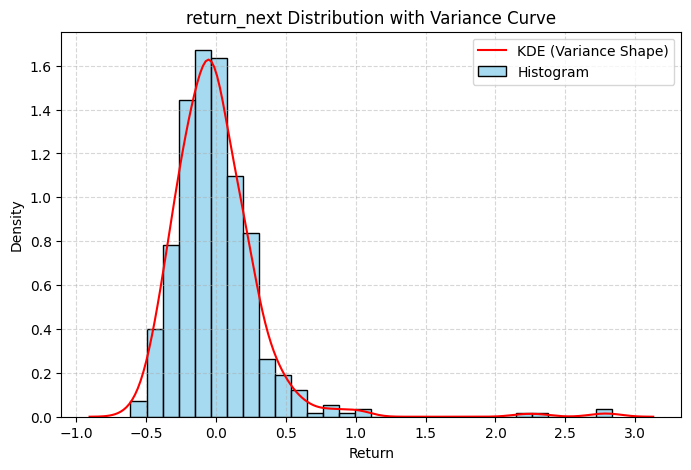

预测均值 MSE：0.213017

--- MSE 对比 ---
         BoW MSE = 0.236168 | 相对均值基线: 1.109x
         W2V MSE = 0.239963 | 相对均值基线: 1.126x
         D2V MSE = 0.227407 | 相对均值基线: 1.068x
        BERT MSE = 0.232718 | 相对均值基线: 1.092x
     MacBERT MSE = 0.228736 | 相对均值基线: 1.074x
     RoBERTa MSE = 0.224951 | 相对均值基线: 1.056x
    BERT-wwm MSE = 0.229118 | 相对均值基线: 1.076x
     ELECTRA MSE = 0.209563 | 相对均值基线: 0.984x
MeanBaseline MSE = 0.213017 | 相对均值基线: 1.000x

======== 正在处理目标：return_2years ========

【词袋模型 + 线性回归】预测目标：return_2years
测试集 MSE：0.112147

【Word2Vec + 均值向量 + 线性回归】预测目标：return_2years
测试集 MSE：0.063551

【Doc2Vec + 线性回归】预测目标：return_2years
测试集 MSE：0.071298

【中文预训练BERT + 回归微调】预测目标：return_2years
第1轮训练损失：0.182401
第2轮训练损失：0.117952
第3轮训练损失：0.109906
测试集 MSE：0.072927

【hfl/chinese-macbert-base + mean pooling 回归微调】预测目标：return_2years
第1轮训练损失：0.127561
第2轮训练损失：0.118242
第3轮训练损失：0.106475
测试集 MSE：0.086354

【hfl/chinese-roberta-wwm-ext + mean pooling 回归微调】预测目标：return_2years
第1轮训练损失：0.129131
第2轮训练损失：0.121113
第3轮训练损失：0.1052

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


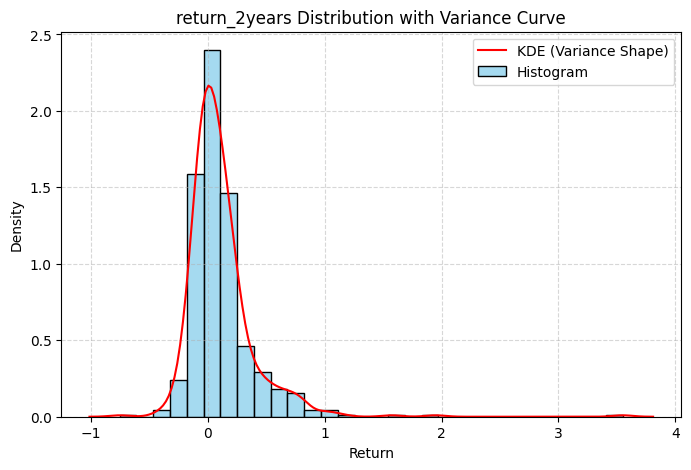

预测均值 MSE：0.049468

--- MSE 对比 ---
         BoW MSE = 0.112147 | 相对均值基线: 2.267x
         W2V MSE = 0.063551 | 相对均值基线: 1.285x
         D2V MSE = 0.071298 | 相对均值基线: 1.441x
        BERT MSE = 0.072927 | 相对均值基线: 1.474x
     MacBERT MSE = 0.086354 | 相对均值基线: 1.746x
     RoBERTa MSE = 0.089426 | 相对均值基线: 1.808x
    BERT-wwm MSE = 0.090472 | 相对均值基线: 1.829x
     ELECTRA MSE = 0.055796 | 相对均值基线: 1.128x
MeanBaseline MSE = 0.049468 | 相对均值基线: 1.000x

===== 所有模型结果对比（MSE） =====

【预测目标：return_next】
       BoW 模型：MSE = 0.236168
       W2V 模型：MSE = 0.239963
       D2V 模型：MSE = 0.227407
      BERT 模型：MSE = 0.232718
   MacBERT 模型：MSE = 0.228736
   RoBERTa 模型：MSE = 0.224951
  BERT-wwm 模型：MSE = 0.229118
   ELECTRA 模型：MSE = 0.209563
MeanBaseline 模型：MSE = 0.213017

【预测目标：return_2years】
       BoW 模型：MSE = 0.112147
       W2V 模型：MSE = 0.063551
       D2V 模型：MSE = 0.071298
      BERT 模型：MSE = 0.072927
   MacBERT 模型：MSE = 0.086354
   RoBERTa 模型：MSE = 0.089426
  BERT-wwm 模型：MSE = 0.090472
   ELECTRA 模型：MSE = 0.0557

In [4]:
#安装依赖包:pip install pandas scikit-learn gensim torch transformers
import matplotlib.pyplot as plt
import seaborn as sns
import math
import random
import os
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import gensim
from gensim.models import Word2Vec, Doc2Vec
from gensim.models.doc2vec import TaggedDocument

import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn, optim
from transformers import BertTokenizer, BertModel
from transformers import AutoTokenizer

# ========== 优化BERT + 回归微调 ==========
def _set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

class MeanPooling(nn.Module):
    """对 last_hidden_state 做 attention_mask 加权的 mean pooling。"""
    def __init__(self):
        super().__init__()
    def forward(self, last_hidden_state, attention_mask):
        # attention_mask: (bs, L) -> (bs, L, 1)
        mask = attention_mask.unsqueeze(-1).type_as(last_hidden_state)
        summed = (last_hidden_state * mask).sum(dim=1)
        denom = mask.sum(dim=1).clamp(min=1e-6)
        return summed / denom

class TransformerRegressor(nn.Module):
    """
    任意中文预训练模型 + 池化 + 回归头
    pooling: 'mean' | 'cls'
    """
    def __init__(self, pretrained_name: str, pooling: str = 'mean', dropout: float = 0.1, freeze_encoder: bool = False):
        super().__init__()
        # 为了便于你直接粘贴，此处在函数内部导入 Auto*，不要求你改顶部import
        from transformers import AutoModel
        self.backbone = AutoModel.from_pretrained(pretrained_name)
        self.pooling = pooling
        self.mean_pool = MeanPooling()
        hidden = self.backbone.config.hidden_size
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, 1)
        )
        if freeze_encoder:
            for p in self.backbone.parameters():
                p.requires_grad = False

    def forward(self, input_ids, attention_mask):
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        if self.pooling == 'mean':
            pooled = self.mean_pool(out.last_hidden_state, attention_mask)
        else:  # 'cls'
            pooled = out.last_hidden_state[:, 0, :]
        return self.head(pooled).squeeze(-1)

def run_transformer_regression(
    df, target_col,
    pretrained_name='hfl/chinese-macbert-base',
    pooling='mean',
    max_len=512,
    epochs=3,
    batch_size=8,
    lr=2e-5,
    weight_decay=1e-2,
    freeze_encoder=False,
    seed=42
):
    """
    通用Runner：可换任意中文模型，只需改 pretrained_name。
    推荐：'hfl/chinese-macbert-base'（稳）,
         'hfl/chinese-roberta-wwm-ext',
         'hfl/chinese-bert-wwm-ext',
         'hfl/chinese-electra-base-discriminator',
         'IDEA-CCNL/Erlangshen-DeBERTa-v3-base-zh'
    """
    print(f"\n【{pretrained_name} + {pooling} pooling 回归微调】预测目标：{target_col}")
    _set_seed(seed)

    tokenizer = AutoTokenizer.from_pretrained(pretrained_name)

    # 复用已有的 ReportDataset 类
    X_train_texts, X_test_texts, y_train, y_test = train_test_split(
        df['report_text'], df[target_col].values, test_size=0.2, random_state=seed
    )
    train_ds = ReportDataset(X_train_texts.tolist(), y_train, tokenizer, max_len=max_len)
    test_ds  = ReportDataset(X_test_texts.tolist(),  y_test,  tokenizer, max_len=max_len)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = TransformerRegressor(
        pretrained_name=pretrained_name,
        pooling=pooling,
        dropout=0.1,
        freeze_encoder=freeze_encoder
    ).to(device)

    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for batch in train_loader:
            optimizer.zero_grad()
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            targets = batch['target'].to(device)
            preds = model(input_ids, attention_mask)
            loss = loss_fn(preds, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"第{epoch+1}轮训练损失：{total_loss / max(1, len(train_loader)):.6f}")

    model.eval()
    preds_list, targets_list = [], []
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            preds = model(input_ids, attention_mask).cpu().numpy()
            preds_list.extend(preds)
            targets_list.extend(batch['target'].numpy())

    mse = mean_squared_error(targets_list, preds_list)
    print(f"测试集 MSE：{mse:.6f}")
    return mse

# 封装
def run_macbert(df, target_col, **kwargs):
    return run_transformer_regression(df, target_col,
                                      pretrained_name='hfl/chinese-macbert-base',
                                      pooling=kwargs.get('pooling', 'mean'),
                                      **{k:v for k,v in kwargs.items() if k!='pooling'})

def run_roberta_wwm(df, target_col, **kwargs):
    return run_transformer_regression(df, target_col,
                                      pretrained_name='hfl/chinese-roberta-wwm-ext',
                                      pooling=kwargs.get('pooling', 'mean'),
                                      **{k:v for k,v in kwargs.items() if k!='pooling'})

def run_bert_wwm(df, target_col, **kwargs):
    return run_transformer_regression(df, target_col,
                                      pretrained_name='hfl/chinese-bert-wwm-ext',
                                      pooling=kwargs.get('pooling', 'mean'),
                                      **{k:v for k,v in kwargs.items() if k!='pooling'})

def run_electra(df, target_col, **kwargs):
    return run_transformer_regression(df, target_col,
                                      pretrained_name='hfl/chinese-electra-base-discriminator',
                                      pooling=kwargs.get('pooling', 'mean'),
                                      **{k:v for k,v in kwargs.items() if k!='pooling'})

def run_deberta_v3(df, target_col, **kwargs):
    # 体量较大，显存不够就换回 MacBERT
    return run_transformer_regression(df, target_col,
                                      pretrained_name='IDEA-CCNL/Erlangshen-DeBERTa-v3-base-zh',
                                      pooling=kwargs.get('pooling', 'mean'),
                                      **{k:v for k,v in kwargs.items() if k!='pooling'})

import os
os.environ.setdefault("HF_ENDPOINT", "https://hf-mirror.com")  

# ==== 1) 安全加载：出错时自动回退到 bert-base-chinese ====
def _safe_load_tokenizer_and_model(name):
    from transformers import AutoTokenizer, AutoModel
    try:
        tok = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
        mdl = AutoModel.from_pretrained(name, trust_remote_code=True)
        print(f"[INFO] Loaded pretrained: {name}")
        return tok, mdl, name
    except Exception as e:
        print(f"[WARN] 加载 {name} 失败：{e}")
        try:
            fallback = 'bert-base-chinese'
            tok = AutoTokenizer.from_pretrained(fallback, trust_remote_code=True)
            mdl = AutoModel.from_pretrained(fallback, trust_remote_code=True)
            print(f"[INFO] 回退到 {fallback}")
            return tok, mdl, fallback
        except Exception as e2:
            raise RuntimeError(f"预训练模型与回退模型均加载失败：{e2}")
            

# ========== 2025误差更小-寻找原因 ==========
def plot_distribution_with_variance(df, target_col):
    """
    绘制直方图 + KDE曲线，展示收益率分布及方差形态
    """
    plt.figure(figsize=(8,5))
    sns.histplot(df[target_col], kde=False, bins=30, color='skyblue', stat='density', label='Histogram')
    sns.kdeplot(df[target_col], color='red', label='KDE (Variance Shape)')
    plt.title(f"{target_col} Distribution with Variance Curve")
    plt.xlabel("Return")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

def baseline_mean_mse(df, target_col):
    """
    用样本均值作为预测值的MSE（无模型基线）
    """
    X_train, X_test, y_train, y_test = make_splits(df, target_col)
    mean_pred = np.full_like(y_test, fill_value=np.mean(y_train), dtype=np.float64)
    mse = mean_squared_error(y_test, mean_pred)
    return mse


# ========== 主函数：两类目标对比 ==========
if __name__ == "__main__":
    targets = ['return_next', 'return_2years']
    results = {}

    for tgt in targets:
        print(f"\n======== 正在处理目标：{tgt} ========")
        results[tgt] = {}

        # 仍然跑你旧的三种基线 + 旧BERT
        results[tgt]['BoW']   = run_bow_lr(df, tgt)
        results[tgt]['W2V']   = run_w2v_avg_lr(df, tgt)
        results[tgt]['D2V']   = run_d2v_lr(df, tgt)
        results[tgt]['BERT']  = run_bert_regression(df, tgt)

        # 新增：更强的中文预训练模型（默认 mean pooling）
        results[tgt]['MacBERT']  = run_macbert(df, tgt, epochs=3, batch_size=8, lr=2e-5, pooling='mean')
        results[tgt]['RoBERTa']  = run_roberta_wwm(df, tgt, epochs=3, batch_size=8, lr=2e-5, pooling='mean')
        results[tgt]['BERT-wwm'] = run_bert_wwm(df, tgt, epochs=3, batch_size=8, lr=2e-5, pooling='mean')
        results[tgt]['ELECTRA']  = run_electra(df, tgt, epochs=3, batch_size=8, lr=2e-5, pooling='mean')
        # 显存足够再开启：
        # results[tgt]['DeBERTaV3'] = run_deberta_v3(df, tgt, epochs=3, batch_size=8, lr=2e-5, pooling='mean')

         # 绘制分布
        plot_distribution_with_variance(df, tgt)

        # 均值预测 MSE
        mean_mse = baseline_mean_mse(df, tgt)
        results[tgt]['MeanBaseline'] = mean_mse
        print(f"预测均值 MSE：{mean_mse:.6f}")

        # 对比分析
        print("\n--- MSE 对比 ---")
        for model_name, mse in results[tgt].items():
            diff_ratio = mse / mean_mse
            print(f"{model_name:>12} MSE = {mse:.6f} | 相对均值基线: {diff_ratio:.3f}x")


    print("\n===== 所有模型结果对比（MSE） =====")
    for tgt in targets:
        print(f"\n【预测目标：{tgt}】")
        for model_name, mse in results[tgt].items():
            print(f"{model_name:>10} 模型：MSE = {mse:.6f}")

